# Allele Collection Summary

Allele collection summary information: Collection, ClinVar

In [1]:
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from plot_utils import *

input_dir = '../1_inputs'
output_dir = '../3_outputs'

In [2]:
allele_collection_df = pl.read_csv(
    f'{output_dir}/varchamp_seq_confirm_alleles_clinvar_gnomad_dbnsfp_struc_scores.tsv', 
    separator='\t', infer_schema_length=100000
)
allele_collection_df.shape

(9153, 525)

## VarChAMP Allele QC

Check the consistency between nucleotide change and its respective AA change

In [3]:
# allele_df = pl.scan_csv(f"{meta_outputs}/varchamp_consolidated_alleles_clinvar_gnomad.tsv", separator="\t", infer_schema_length=10000)
# allele_df = allele_df.collect()
# allele_df

In [4]:
# ## QC
# from Bio.Seq import Seq
# aa_single_to_three = {
#     'A': 'Ala',  # Alanine
#     'R': 'Arg',  # Arginine
#     'N': 'Asn',  # Asparagine
#     'D': 'Asp',  # Aspartic acid
#     'C': 'Cys',  # Cysteine
#     'Q': 'Gln',  # Glutamine
#     'E': 'Glu',  # Glutamic acid
#     'G': 'Gly',  # Glycine
#     'H': 'His',  # Histidine
#     'I': 'Ile',  # Isoleucine
#     'L': 'Leu',  # Leucine
#     'K': 'Lys',  # Lysine
#     'M': 'Met',  # Methionine
#     'F': 'Phe',  # Phenylalanine
#     'P': 'Pro',  # Proline
#     'S': 'Ser',  # Serine
#     'T': 'Thr',  # Threonine
#     'W': 'Trp',  # Tryptophan
#     'Y': 'Tyr',  # Tyrosine
#     'V': 'Val'   # Valine
# }

# for row in allele_df.iter_rows(named=True): #.filter(pl.col("hgvs_nt").is_duplicated()).sort(by="hgvs_nt")
#     # hgvs_df = dat_info.filter(pl.col("hgvs_nt")==hgvs_nt)
#     nuc_pos = int(row["nt_change"][:-3])
#     nuc_r, nuc_v = row["nt_change"].split(">")[0][-1], row["nt_change"].split(">")[-1][-1]

#     nuc_var = row["sequence"][nuc_pos-1] ## row["ref_cds"][nuc_pos-1], 
#     nuc_seq = row["sequence"]
#     # print(nuc_r, nuc_v, nuc_ref, nuc_var)
#     prot_pos = int(row["aa_change"][3:-3])
#     prot_r, prot_v = row["aa_change"][:3], row["aa_change"][-3:]
#     prot_ref_seq = Seq(nuc_seq[:nuc_pos-1]+nuc_r+nuc_seq[nuc_pos:]).translate()
#     prot_var_seq = Seq(nuc_seq).translate()
#     try:
#         prot_ref, prot_var = aa_single_to_three[prot_ref_seq[prot_pos-1]], aa_single_to_three[prot_var_seq[prot_pos-1]]
#         # print(prot_r, prot_v, prot_ref, prot_var)
#         if nuc_v != nuc_var or prot_r != prot_ref or prot_v != prot_var:
#             print("Original annotations:", row["aa_change"], row["nt_change"])
#             print(f"Actual Nuc Var:{nuc_var} | " + \
#                 f"Actual Prot Ref:{prot_ref}, Var:{prot_var}")
#             print("========================================================")
#     except:
#         print(row["aa_change"], row["nt_change"], "| Protein seq len ONLY:", len(prot_ref_seq))
#         print("========================================================")
#     # break

## Allele Collection Summary

In [5]:
collections = allele_collection_df.select("collection").drop_nulls().to_series().unique().to_list()

for coll in collections:
    coll_df = allele_collection_df.filter(pl.col("collection") == coll)
    genes = coll_df.select("symbol").to_series().unique().to_list()
    alleles = coll_df.select(["symbol", "aa_change"]).unique()
    print(f"For collection {coll}, there are {len(genes)} genes and {alleles.shape[0]} alleles.")

all_genes = allele_collection_df.select("symbol").unique().shape[0]
all_alleles = allele_collection_df.select(["symbol", "aa_change"]).unique().shape[0]
print(f"Overall, there are {all_genes} genes and {all_alleles} alleles.")

For collection RC4, there are 1137 genes and 2946 alleles.
For collection Edgotyping3, there are 71 genes and 1465 alleles.
For collection CEGS2, there are 998 genes and 4296 alleles.
Overall, there are 1691 genes and 8750 alleles.


## ClinVar Per Year Summary

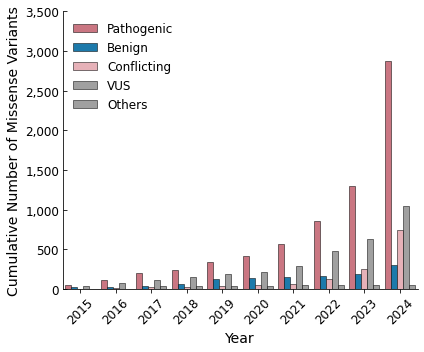

In [6]:
def plot_clinvar(clinvar_df, save_fig=False):
    
    date_col = 'LastEvaluated'

    # Convert LastEvaluated to datetime, forcing invalid to become NaT
    clinvar_df[date_col] = pd.to_datetime(clinvar_df[date_col], errors='coerce')

    # Drop rows where LastEvaluated couldn't be parsed (NaT)
    clinvar_df = clinvar_df.dropna(subset=[date_col]).copy()
    
    clinsig_col = 'clinvar_clnsig_clean'

    # Extract year
    clinvar_df['Year'] = clinvar_df[date_col].dt.year

    # Group by Year and ClinSig
    yearly_counts = (
        clinvar_df
        .groupby(['Year', clinsig_col])
        .size()
        .unstack(fill_value=0)
    )

    # Sort the index by year
    yearly_counts = yearly_counts.sort_index()

    # Only show rows from 2015 and after
    yearly_counts = yearly_counts.loc[
        (yearly_counts.index >= 2015) & 
        (yearly_counts.index <= 2024)]

    # Reorder columns if needed
    desired_order = ['1_Pathogenic', '2_Benign', '3_Conflicting', '4_VUS', '5_Others']
    yearly_counts = yearly_counts[[col for col in desired_order if col in yearly_counts.columns]]

    # Cumulative counts
    yearly_cum_counts = yearly_counts.cumsum()

    # Color mapping
    # color_map = {
    #     '2_Benign': 'forestgreen',
    #     '1_Pathogenic': 'firebrick',
    #     '4_VUS': 'royalblue',
    #     '3_Conflicting': 'gold',
    #     '5_Others': 'darkgray'
    # }
    color_map = palette_dict["clinvar_clnsig_clean"]

    fig, ax = plt.subplots(figsize=(6,5))

    # Plot
    ax = yearly_cum_counts.plot(
        kind='bar',
        ax=ax,
        width=0.85,
        stacked=False,
        color=[color_map.get(col, 'gray') for col in yearly_cum_counts.columns],
        edgecolor='black',
        linewidth=0.5
    )

    # Tighten x-limits so there's minimal extra space
    num_years = len(yearly_cum_counts.index)
    ax.set_xlim(-0.5, num_years - 0.5)

    # Set integer x-ticks and labels
    ax.set_xticks(range(num_years))
    ax.set_xticklabels(yearly_cum_counts.index, rotation=45)

    # Format large y-values with commas, no scientific notation
    ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))

    # Increase tick label size
    ax.tick_params(axis='both', labelsize=12)


    ax.spines['left'].set_visible(True)          # Ensure the left spine is visible
    ax.spines['right'].set_visible(False)        # Hide the right spine if you like
    ax.yaxis.set_label_position("left")          # Keep the axis label on the left
    ax.yaxis.set_ticks_position("left")          # Ticks on the left spine

    # direction='in' => tick marks go inside the plot
    ax.tick_params(axis='y', direction='in')

    # Remove the top spine if desired
    ax.spines['top'].set_visible(False)

    # Axis labels & title
    ax.set_xlabel("Year", fontsize=14)
    ax.set_ylabel("Cumulative Number of Missense Variants", fontsize=14)
    # ax.set_title("Clinical Significance of Missense Variants over the Years", fontsize=14)
    
    # New legend without the prefix
    handles, labels = ax.get_legend_handles_labels()
    new_labels = [label.split('_', 1)[1] for label in labels]
    ax.legend(handles, new_labels, title="", fontsize=12, frameon=False, loc='upper left')


    ticks = ax.get_yticks()
    # Set the top limit to the last tick
    ax.set_ylim(top=ticks[-1])

    plt.tight_layout()
    if save_fig:
        plt.savefig(figure_output_dir / "clinvar_missense_variants_clinical_significance_year.png", dpi=300)
        
    plt.show()
    
    
plot_clinvar(allele_collection_df.to_pandas(), save_fig=False)

In [8]:
allele_collection_df_pd = allele_collection_df.to_pandas()
allele_collection_df_pd.clinvar_clnsig_clean.value_counts()

clinvar_clnsig_clean
1_Pathogenic     4727
4_VUS            1205
3_Conflicting    1116
6_No_ClinVar      961
2_Benign          703
5_Others          441
Name: count, dtype: int64

In [12]:
allele_collection_df_pd[allele_collection_df_pd["clinvar_clnsig_clean"] == "3_Conflicting"].ClinicalSignificance.unique()

array(['Conflicting classifications of pathogenicity',
       'Conflicting classifications of pathogenicity; other',
       'Conflicting classifications of pathogenicity; risk factor',
       'Conflicting classifications of pathogenicity; association',
       'Conflicting classifications of pathogenicity; association; risk factor'],
      dtype=object)

In [16]:
allele_collection_df_pd[allele_collection_df_pd['#AlleleID'].isna()].clinvar_clnsig_clean.value_counts()

clinvar_clnsig_clean
6_No_ClinVar    961
Name: count, dtype: int64